In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.compose import ColumnTransformer

from pathlib import Path
import os
import pickle

In [2]:
# Establish directories
cdir = Path.cwd()
root = cdir.parent
ds_dir = root/'data/'
res_dir = cdir/'results'

os.makedirs(res_dir,exist_ok=True)

# Functions
def save_result(file,filename:str,dir=res_dir):
    with open(f'{dir}/'+filename+'.pkl', 'wb') as save:
        pickle.dump(file, save)
    return file

def split_data(X, y, test_size:float, state:int):
    X_train, X_test, y_train, y_test = train_test_split(
        X,y,test_size=test_size,stratify=y,random_state=state
    )
    return X_train, X_test, y_train, y_test

def get_baseline(model):
    p = model.mean()
    return pd.DataFrame({
        'Baseline':
        {'Precision':p,
         'Recall':1,
         'Accuracy':p,
         'F1':2*p/(1+p),
         'Roc auc':0.5,
         'Flagged':np.nan
        }}
    )

def logit_pipeline(X_set,y_set):

    numeric = X_set.select_dtypes(include='number').columns.tolist()
    category = X_set.select_dtypes(exclude='number').columns.tolist()

    prep = ColumnTransformer([
        ('num', make_pipeline(SimpleImputer(strategy='median'),StandardScaler()), numeric),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'),category)
    ])

    pipe = Pipeline([
        ('prep',prep),
        ('model', LogisticRegression(max_iter=1000, random_state=0))
    ])

    return pipe.fit(X_set,y_set)

def xgboost_pipeline(X_set,y_set,params:dict,scoring:dict,refit:str,cv=5):
    numeric = X_set.select_dtypes(include='number').columns.tolist()
    category = X_set.select_dtypes(exclude='number').columns.tolist()

    prep = ColumnTransformer([
        ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), numeric),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), category)
    ])

    pipe = Pipeline([
        ('prep', prep),
        ('model', XGBClassifier(objective='binary:logistic', random_state=0))
    ])

    xgb_cv = GridSearchCV(
        pipe,
        params,
        scoring=scoring,
        cv=cv,
        refit=refit
    )

    return xgb_cv.fit(X_set, y_set)

def train_scores(model,model_name:str):
    cv_model = pd.DataFrame(model.cv_results_)
    metric_scores = {
    'mean_test_precision':'precision',
    'mean_test_recall':'recall',
    'mean_test_f1':'f1',
    'mean_test_accuracy':'accuracy',
    'mean_test_roc_auc':'roc auc'
    }
    best_estimator_result = cv_model.loc[cv_model['mean_test_f1'].idxmax(),:]
    return pd.DataFrame({model_name:{name.capitalize(): best_estimator_result[col] for col,name in metric_scores.items()}})

def get_metrics(X_set, y_set, model_name: str, model, threshold: float = 0.5):
    proba = model.predict_proba(X_set)[:, 1]
    pred = (proba >= threshold).astype(int)

    return pd.DataFrame({
        model_name:
        {'Precision': precision_score(y_set, pred, zero_division=0),
        'Recall':    recall_score(y_set, pred),
        'F1':        f1_score(y_set, pred),
        'Accuracy':  accuracy_score(y_set, pred),
        'Roc auc':   roc_auc_score(y_set, proba),
        'Flagged':   pred.mean()}
    })

def make_confusion_matrix(model, X_set, y_set):
    model_pred = model.predict(X_set)
    cm = confusion_matrix(y_set, model_pred, labels=model.classes_)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
    disp.plot(values_format='d')

In [3]:
# Import dataset
df = pd.read_csv(ds_dir/'customer_churn_clean.csv', index_col=0)
df.head()

,customer_id,gender,region,subscription_plan,payment_method,age,days_since_last_login,customer_service_calls,monthly_spend,churn
0,10001,male,east,basic,paypal,27.0,27,1.0,61.08,0
1,10002,unknown,west,pro,paypal,55.0,146,2.0,73.09,0
2,10003,female,west,pro,e-wallet,NaN,147,2.0,116.30,1
3,10004,female,south,basic,credit_card,NaN,34,1.0,0.58,1
4,10005,male,north,basic,crypto,30.0,146,3.0,46.35,1


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10300 entries, 0 to 10299
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             10300 non-null  int64  
 1   gender                  10300 non-null  str    
 2   region                  10300 non-null  str    
 3   subscription_plan       10300 non-null  str    
 4   payment_method          9575 non-null   str    
 5   age                     8718 non-null   float64
 6   days_since_last_login   10300 non-null  int64  
 7   customer_service_calls  10248 non-null  float64
 8   monthly_spend           9715 non-null   float64
 9   churn                   10300 non-null  int64  
dtypes: float64(3), int64(3), str(4)
memory usage: 804.8 KB


In [5]:
# drop unnecessary columns
df1=df.drop(['customer_id','gender','payment_method','age'], axis=1)
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 10300 entries, 0 to 10299
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   region                  10300 non-null  str    
 1   subscription_plan       10300 non-null  str    
 2   days_since_last_login   10300 non-null  int64  
 3   customer_service_calls  10248 non-null  float64
 4   monthly_spend           9715 non-null   float64
 5   churn                   10300 non-null  int64  
dtypes: float64(2), int64(2), str(2)
memory usage: 482.9 KB


#### Split Data
* Training Set: 60%
* Validation Set: 20%
* Test Set: 20%

In [6]:
# Set predictors and target variable
X = df1.drop('churn',axis=1)
y = df1['churn']

# Split data into: TRAINING SET, VALIDATION SET, TEST SET
X_train,X_test,y_train,y_test = split_data(X,y,0.2,42)
X_tr,X_val,y_tr,y_val = split_data(X_train,y_train,0.25,0)

#### Get Baseline Metrics Score

In [7]:
# Get baseline score
model_score = 'Model Scores'
model = y_tr
model_result = save_result(get_baseline(model),model_score)
model_result

,Baseline
Precision,0.761974
Recall,1.000000
Accuracy,0.761974
F1,0.864910
Roc auc,0.500000
Flagged,NaN


#### Make Model

In [8]:
logit_model = logit_pipeline(X_tr, y_tr)
val_logit_result = get_metrics(X_val, y_val, 'Logit Validation Result', logit_model)
test_logit_result = get_metrics(X_test,y_test,'Logit Test Result',logit_model)
result = pd.concat([val_logit_result,test_logit_result],axis=1)
result['Logit Score Diff'] = result['Logit Validation Result']-result['Logit Test Result']
result = pd.concat([model_result,result],axis=1)
save_result(result,'Logistic Regression Scores')

,Baseline,Logit Validation Result,Logit Test Result,Logit Score Diff
Precision,0.761974,0.789280,0.795418,-0.006138
Recall,1.000000,0.956688,0.950955,0.005732
Accuracy,0.761974,0.772330,0.776214,-0.003883
F1,0.864910,0.864958,0.866261,-0.001302
Roc auc,0.500000,0.730597,0.718606,0.011991
Flagged,NaN,0.923786,0.911165,0.012621


In [9]:
# XGBoost
# Set params:
params = {
    'model__n_estimators':     [100, 300, 500],
    'model__learning_rate':    [0.01, 0.05],
    'model__max_depth':        [3, 4, 5],
    'model__subsample':        [0.7, 0.8],
    'model__colsample_bytree': [0.5, 0.7, 0.8],
    'model__min_child_weight': [1, 3, 5],
}

# Set scoring:
scoring = {
    'precision':'precision',
    'recall':'recall',
    'f1':'f1',
    'accuracy':'accuracy',
    'roc_auc':'roc_auc'
}

# Set cross-validation folds
cv = 5

# Build the model
xgb_cv = xgboost_pipeline(X_tr, y_tr,params,scoring,'f1')

In [10]:
xgb_cv.best_params_

{'model__colsample_bytree': 0.8,
 'model__learning_rate': 0.01,
 'model__max_depth': 3,
 'model__min_child_weight': 5,
 'model__n_estimators': 300,
 'model__subsample': 0.8}

In [11]:
best_base_learner = train_scores(xgb_cv,'Best Base Score')
val_xgb_result = get_metrics(X_val, y_val, 'XGBoost Validation Score', xgb_cv)
test_xgb_result = get_metrics(X_test, y_test, 'XGBoost Test Score', xgb_cv)
save_result(pd.concat([best_base_learner, val_xgb_result, test_xgb_result], axis=1),'XGBoost Model Metric Scores')

,Best Base Score,XGBoost Validation Score,XGBoost Test Score
Precision,0.782436,0.777608,0.778004
Recall,0.975154,0.973248,0.973248
F1,0.868220,0.864498,0.864743
Accuracy,0.774434,0.767476,0.767961
Roc auc,0.735217,0.726239,0.710716
Flagged,NaN,0.953883,0.953398


In [13]:
cv = StratifiedKFold(5, shuffle=True, random_state=42)
table = pd.DataFrame({
    'ROC AUC':{
        'Logistic Model':cross_val_score(logit_model, X_tr, y_tr, cv=cv, scoring='roc_auc').mean(),
        'XGBoost Model':xgb_cv.cv_results_['mean_test_roc_auc'][xgb_cv.best_index_]
    }
})
table['% Diff'] = (table['ROC AUC'].diff()*100).round(2)
save_result(table,'ROC AUC Diff Table')

,ROC AUC,% Diff
Logistic Model,0.743817,NaN
XGBoost Model,0.735217,-0.86


Model results shows that `Logisti Model` performs ≈ 2.82 higher AUC than `XGBoost Model`, therefore, `Logistic Model` is the selected model for this project.  

#### Confusion Matrix (Logistic Model)

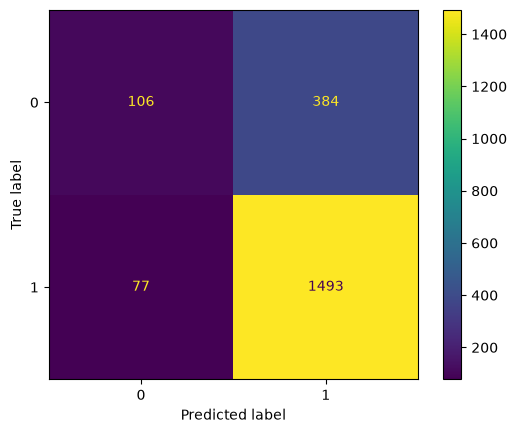

In [14]:
make_confusion_matrix(logit_model,X_test, y_test)

In [16]:
table2 = pd.concat([val_logit_result,val_xgb_result],axis=1)
table2['% Diff'] = ((table2['Logit Validation Result']-table2['XGBoost Validation Score'])*100).round(3)
save_result(table2,'Model Performance Comparison')

,Logit Validation Result,XGBoost Validation Score,% Diff
Precision,0.789280,0.777608,1.167
Recall,0.956688,0.973248,-1.656
F1,0.864958,0.864498,0.046
Accuracy,0.772330,0.767476,0.485
Roc auc,0.730597,0.726239,0.436
Flagged,0.923786,0.953883,-3.010
